# Homework 2: emissions and trade

The question and submission instructions are in `assignment.pdf`.

`data/co2_2023.csv` contains one country per row for 2023, with population and territorial and consumption-based CO2 emissions. The estimates come from Our World in Data and the Global Carbon Budget. `data/countries.geojson` contains Natural Earth country names, identifiers and boundary geometries. Definitions and sources are in `data/README.md`.

In [1]:
import pandas as pd

emissions = pd.read_csv("data/co2_2023.csv")
emissions.head()

,country,iso_code,year,population,co2,co2_per_capita,consumption_co2,consumption_co2_per_capita
0,Afghanistan,AFG,2023,41454762.0,10.516,0.254,NaN,NaN
1,Albania,ALB,2023,2811660.0,4.417,1.571,5.382,1.914
2,Algeria,DZA,2023,46164222.0,202.847,4.394,NaN,NaN
3,Angola,AGO,2023,36749909.0,21.675,0.590,NaN,NaN
4,Argentina,ARG,2023,45538402.0,178.407,3.918,185.666,4.077


In [2]:
import geopandas as gpd

countries = gpd.read_file("data/countries.geojson")
countries.head()

,iso_code,map_name,geometry
0,FJI,Fiji,"MULTIPOLYGON (((180 -16.06713, 180 -16.55522, ..."
1,TZA,United Republic of Tanzania,"POLYGON ((33.90371 -0.95, 34.07262 -1.05982, 3..."
2,ESH,Western Sahara,"POLYGON ((-8.66559 27.65643, -8.66512 27.58948..."
3,CAN,Canada,"MULTIPOLYGON (((-122.84 49, -122.97421 49.0025..."
4,USA,United States of America,"MULTIPOLYGON (((-122.84 49, -120 49, -117.0312..."


## Figure: how trade changes CO₂ per person

Map the gap between consumption-based and territorial emissions per person in 2023.
A positive gap means a country consumes more CO₂ than it emits at home (it imports emissions);
a negative gap means it exports emissions in the goods it sells.

In [3]:
import matplotlib.pyplot as plt

In [4]:
# Keep every map polygon; validate checks each country code appears once in each table.
world = countries.merge(emissions, on="iso_code", how="left", validate="one_to_one", indicator=True)
# Map areas with no emissions row at all (shown grey with the missing values).
print(world.loc[world["_merge"] != "both", ["iso_code", "map_name"]])

    iso_code                             map_name
2        ESH                       Western Sahara
20       FLK                     Falkland Islands
23       ATF  French Southern and Antarctic Lands
45       PRI                          Puerto Rico
159   NE_CYN                      Northern Cyprus
166   NE_SOL                           Somaliland
173   NE_KOS                               Kosovo


In [5]:
# Trade adjustment: consumption-based minus territorial, in tonnes per person.
world["trade_gap"] = world["consumption_co2_per_capita"] - world["co2_per_capita"]
has_gap = world["trade_gap"].notna()
print("Countries with both measures:", has_gap.sum())
print("Raised by trade:", (world["trade_gap"] > 0).sum())
print("Lowered by trade:", (world["trade_gap"] < 0).sum())
world.loc[has_gap].sort_values("trade_gap")[["map_name", "co2_per_capita", "consumption_co2_per_capita", "trade_gap"]].round(2)

Countries with both measures: 115
Raised by trade: 90
Lowered by trade: 25


,map_name,co2_per_capita,consumption_co2_per_capita,trade_gap
85,Qatar,40.13,27.60,-12.53
174,Trinidad and Tobago,23.64,14.87,-8.77
149,Brunei,27.24,19.34,-7.90
5,Kazakhstan,14.08,10.46,-3.62
18,Russia,11.92,9.67,-2.25
...,...,...,...,...
76,Israel,5.98,9.54,3.56
119,Latvia,3.50,7.10,3.60
150,Slovenia,5.67,9.32,3.65
129,Belgium,7.23,16.78,9.55


In [6]:
# Equal Earth keeps country areas comparable, as in the mapping lecture.
projected = world.to_crs("EPSG:8857")

In [7]:
# The eight largest increases and eight largest decreases, for the bar panel.
ranked = projected.loc[projected["trade_gap"].notna()].sort_values("trade_gap")
extremes = pd.concat([ranked.head(8), ranked.tail(8)])
# Red where trade raises emissions per person, blue where it lowers them (same ends as the map colours).
bar_colours = ["#B2182B" if gap > 0 else "#2166AC" for gap in extremes["trade_gap"]]
extremes[["map_name", "co2_per_capita", "consumption_co2_per_capita", "trade_gap"]].round(1)

,map_name,co2_per_capita,consumption_co2_per_capita,trade_gap
85,Qatar,40.1,27.6,-12.5
174,Trinidad and Tobago,23.6,14.9,-8.8
149,Brunei,27.2,19.3,-7.9
5,Kazakhstan,14.1,10.5,-3.6
18,Russia,11.9,9.7,-2.2
97,Mongolia,12.9,10.7,-2.2
25,South Africa,6.9,5.1,-1.8
107,Iran,8.7,7.4,-1.3
49,Botswana,2.9,5.8,2.9
142,Denmark,4.8,8.3,3.5


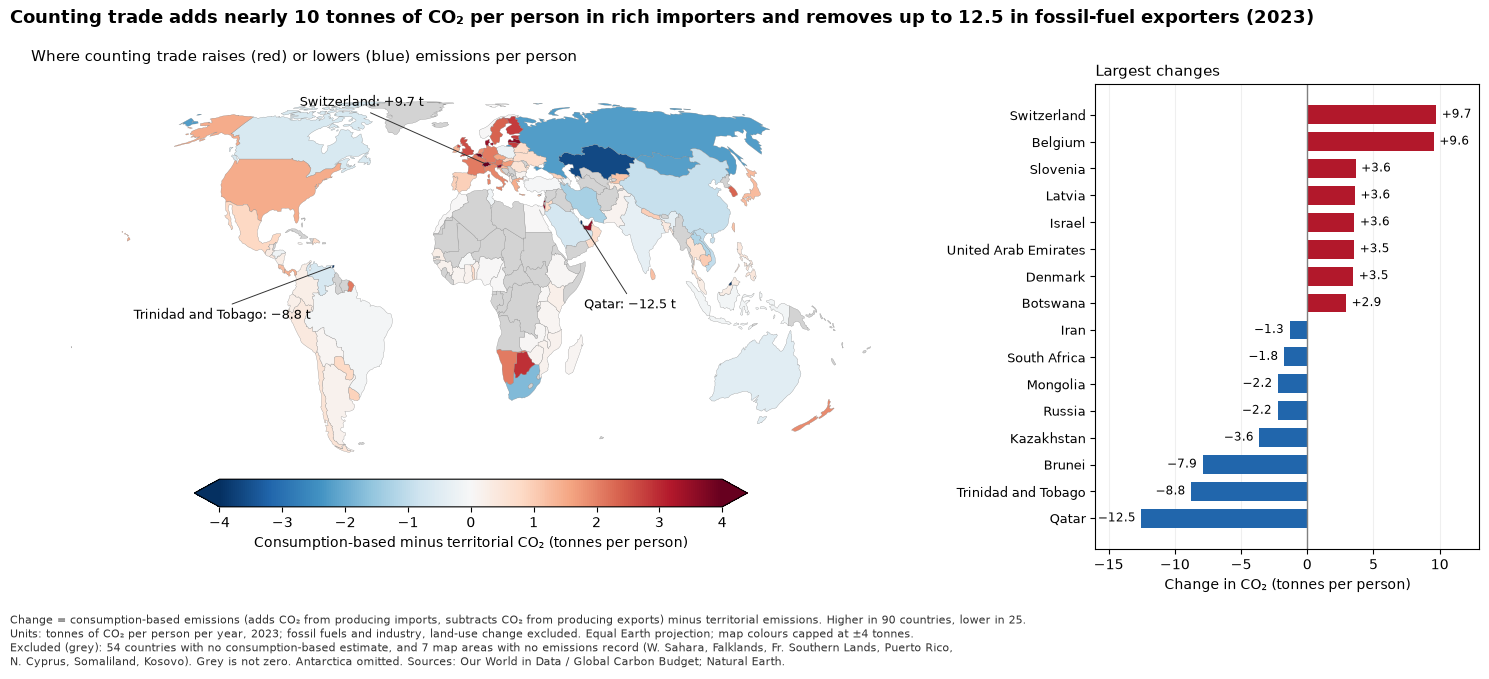

In [8]:
# width_ratios gives the map more room than the bar chart.
fig, (ax_map, ax_bar) = plt.subplots(1, 2, figsize=(15, 6.8), width_ratios=[2.4, 1])

# --- Left: where trade raises or lowers emissions per person ---
# RdBu_r runs blue -> white -> red. vmin and vmax are equal and opposite, so white means zero change.
# Countries beyond ±4 tonnes take the darkest colour; the bar chart gives their exact values.
projected.plot(column="trade_gap", cmap="RdBu_r", vmin=-4, vmax=4, legend=True, ax=ax_map,
               edgecolor="grey", linewidth=0.2,
               legend_kwds={"label": "Consumption-based minus territorial CO₂ (tonnes per person)",
                            "orientation": "horizontal", "shrink": 0.6, "pad": 0.02},
               missing_kwds={"color": "lightgrey", "label": "No estimate"})
ax_map.set_axis_off()
ax_map.set_title("Where counting trade raises (red) or lowers (blue) emissions per person",
                 loc="left", fontsize=11)

# Point to the largest changes; these countries are too small to see on a world map.
# (offset, vertical alignment): va="bottom" puts the label above the line end, "top" below it.
callouts = {"CHE": ((-90, 40), "bottom"), "QAT": ((35, -55), "top"), "TTO": ((-80, -30), "top")}
for code, (offset, valign) in callouts.items():
    row = projected.loc[projected["iso_code"].eq(code)].iloc[0]
    point = row.geometry.representative_point()
    # replace() swaps the hyphen for a proper minus sign.
    label = f"{row['map_name']}: {row['trade_gap']:+.1f} t".replace("-", "−")
    ax_map.annotate(label, (point.x, point.y),
                    xytext=offset, textcoords="offset points", fontsize=9, ha="center", va=valign,
                    # relpos attaches the line to the label's bottom (0) or top (1) edge, not its middle.
                    arrowprops={"arrowstyle": "-", "color": "#333333", "linewidth": 0.7,
                                "relpos": (0.5, 0) if valign == "bottom" else (0.5, 1)})

# --- Right: by how much, for the largest changes ---
ax_bar.barh(extremes["map_name"], extremes["trade_gap"], color=bar_colours, height=0.7)
ax_bar.axvline(0, color="grey", linewidth=1)
# Write each value just past the end of its bar.
for name, gap in zip(extremes["map_name"], extremes["trade_gap"]):
    offset = (4, 0) if gap > 0 else (-4, 0)
    ax_bar.annotate(f"{gap:+.1f}".replace("-", "−"), (gap, name), xytext=offset, textcoords="offset points",
                    ha="left" if gap > 0 else "right", va="center", fontsize=8.5)
ax_bar.set(xlim=(-16, 13), xlabel="Change in CO₂ (tonnes per person)")
ax_bar.set_title("Largest changes", loc="left", fontsize=11)
ax_bar.tick_params(axis="y", labelsize=9)
ax_bar.grid(axis="x", alpha=0.2)
ax_bar.set_axisbelow(True)

fig.suptitle("Counting trade adds nearly 10 tonnes of CO₂ per person in rich importers and removes up to 12.5 in fossil-fuel exporters (2023)",
             x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.text(0.01, 0.015,
         "Change = consumption-based emissions (adds CO₂ from producing imports, subtracts CO₂ from producing exports) minus territorial emissions. "
         "Higher in 90 countries, lower in 25.\n"
         "Units: tonnes of CO₂ per person per year, 2023; fossil fuels and industry, land-use change excluded. Equal Earth projection; map colours capped at ±4 tonnes.\n"
         "Excluded (grey): 54 countries with no consumption-based estimate, and 7 map areas with no emissions record (W. Sahara, Falklands, Fr. Southern Lands, Puerto Rico,\n"
         "N. Cyprus, Somaliland, Kosovo). Grey is not zero. Antarctica omitted. Sources: Our World in Data / Global Carbon Budget; Natural Earth.",
         fontsize=8, color="#333333")
# Reserve the bottom for the notes and the top for the headline; rect is (left, bottom, right, top).
fig.tight_layout(rect=(0, 0.1, 1, 0.97))
fig.savefig("figures/submission.png", dpi=200, bbox_inches="tight")
plt.show()